# Homework - Session 3

This question involves the use of simple linear regression on the Auto
data set:

- (a) Use the `sm.OLS()` function to perform a simple linear regression
with mpg as the response and horsepower as the predictor. Use
the `summarize()` function to print the results. Comment on the
output:

    - i. Is there a relationship between the predictor and the response?
  
    - ii. How strong is the relationship between the predictor and
    the response?
  
    - iii. Is the relationship between the predictor and the response
    positive or negative?
  
    - iv. What is the predicted mpg associated with a horsepower of
    98? What are the associated 95 % confidence and prediction
    intervals?

- (b) Plot the response and the predictor in a new set of axes ax. Use
the `regplot()` function from `seaborn` to display the least squares regression line.

In [ ]:
!pip install ISLP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from ISLP import load_data
from ISLP.models import ModelSpec as MS, summarize

In [ ]:
Auto = load_data('Auto')
print(Auto.shape)
Auto.head()

## (a) Regressing `mpg` on `horsepower` with `sm.OLS()`

We build the design matrix (intercept + `horsepower`) with `ModelSpec`, then fit the model by least squares.

In [4]:
X = MS(['horsepower']).fit_transform(Auto)   # columns: intercept, horsepower
y = Auto['mpg']

model = sm.OLS(y, X)
results = model.fit()
summarize(results)

,coef,std err,t,P>|t|
intercept,39.9359,0.717,55.660,0.0
horsepower,-0.1578,0.006,-24.489,0.0


Use R-squared to assess the strength of the relationship:

In [5]:
print(f"R²                         : {results.rsquared:.4f}")

R²                         : 0.6059


### Comments

**i. Is there a relationship between the predictor and the response?**
Yes. We test $H_0 : \beta_1 = 0$ against $H_1 : \beta_1 \neq 0$. The $t$-statistic for `horsepower` is about $-24.5$ and the p-value is essentially zero (< $10^{-80}$). We therefore strongly reject $H_0$: there is a statistically significant relationship between `horsepower` and `mpg`.

**ii. How strong is the relationship between the predictor and the response?**
- $R^2 \approx 0.606$: about **61% of the variance in `mpg`** is explained by `horsepower` alone. This is a fairly strong relationship for a single predictor.

The relationship is clear, but a substantial share of the variability remains unexplained (and, as the plot will show, the relationship is not perfectly linear).

**iii. Is the relationship between the predictor and the response positive or negative?**
**Negative**: $\hat\beta_1 \approx -0.158$. Each additional unit of horsepower is associated, on average, with a decrease of about 0.16 mpg (roughly 1.6 mpg less for every additional 10 hp). More powerful cars tend to be less fuel-efficient.

**iv. What is the predicted `mpg` for `horsepower = 98`? What are the associated 95% confidence and prediction intervals?**

We reuse the same transformation (`ModelSpec`) to build the design matrix for the new data point :

In [8]:
design = MS(['horsepower']).fit(Auto)
new_df = pd.DataFrame({'horsepower': [98]})
newX = design.transform(new_df)
newX

,intercept,horsepower
0,1.0,98


Then call `get_prediction()` on the design matrix using coefficients stored in `results` : 

In [9]:
new_predictions = results.get_prediction(newX)
print("Predicted mpg:", new_predictions.predicted_mean)

Predicted mpg: [24.46707715]


In [6]:
# 95% confidence interval (for the mean mpg)
new_predictions.conf_int(alpha=0.05)

array([[23.97307896, 24.96107534]])

In [7]:
# 95% prediction interval (for an individual car)
new_predictions.conf_int(obs=True, alpha=0.05)

array([[14.80939607, 34.12475823]])

For a car with 98 hp:

- **predicted mpg**: $\hat y = 39.936 - 0.158 \times 98 \approx$ **24.47 mpg**;
- **95% confidence interval**: **[23.97, 24.96]**. It covers the *average* `mpg` of all cars with 98 hp;
- **95% prediction interval**: **[14.81, 34.12]**. It covers the `mpg` of *one particular* car with 98 hp.

The prediction interval is much wider because, in addition to the uncertainty in the estimated coefficients, it accounts for the irreducible error $\varepsilon$ (of the order of the RSE ≈ 4.9). Both intervals are centred on the same predicted value.

## (b) Scatter plot and least squares line with `seaborn.regplot()`

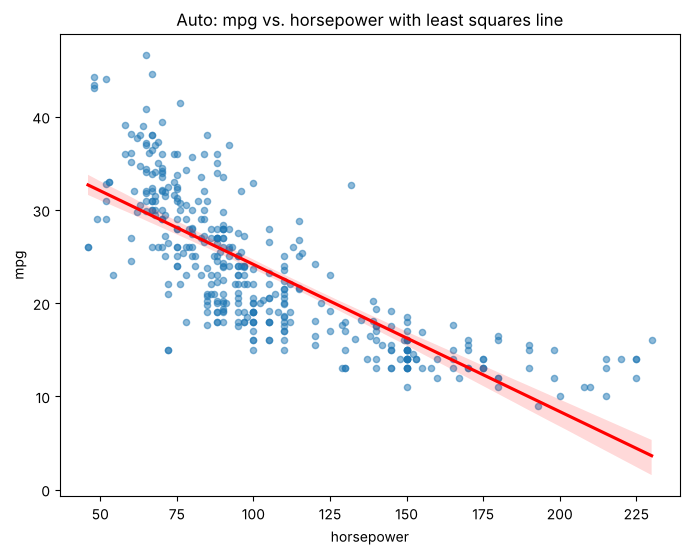

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(x='horsepower', y='mpg', data=Auto, ax=ax,
            scatter_kws={'alpha': 0.5, 's': 20},
            line_kws={'color': 'red'})
ax.set_xlabel('horsepower')
ax.set_ylabel('mpg')
ax.set_title('Auto: mpg vs. horsepower with least squares line');

**Comment.** The downward-sloping line confirms the negative relationship. However, the scatter plot shows clear **curvature**: the line overestimates `mpg` for low and high horsepower values and underestimates it for intermediate values. A model that is linear in `horsepower` is therefore not fully appropriate. Adding a quadratic term ($horsepower^2$) or transforming the variables (e.g. $\log$) would likely improve the fit, which a residual plot can confirm.

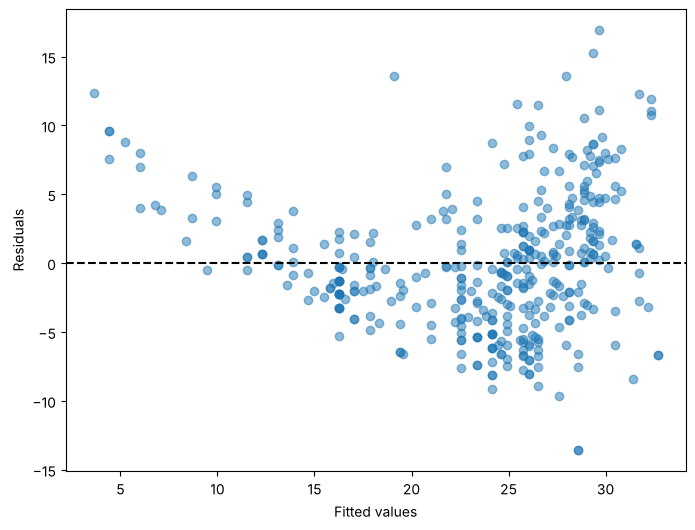

In [9]:
# (Optional) Residual plot to confirm the non-linearity
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(results.fittedvalues, results.resid, alpha=0.5)
ax.axhline(0, c='k', ls='--')
ax.set_xlabel('Fitted values')
ax.set_ylabel('Residuals');